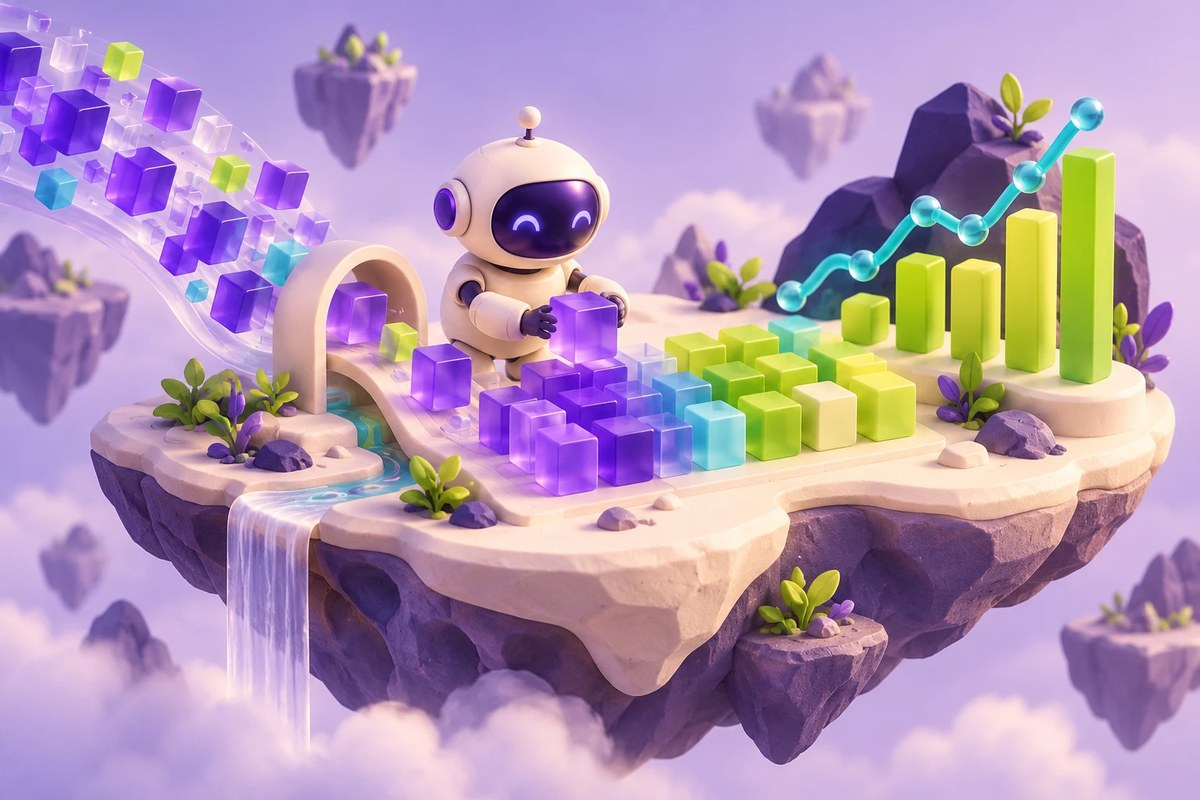

AI PATH · Python для машинного обучения · Урок 051

# Листаем историю в Jupyter

Сцены, Markdown и навигация на ipywidgets

**Архивный учебный материал.** Код и сохранённые результаты относятся к исходному ноутбуку. Оформление не означает новый запуск или подтверждение старых метрик. Перед выполнением проверьте зависимости и ограничения.

<a id="ai-051-goal"></a>
## Что вы разберёте

Понять, как список сцен, текущий индекс и обработчики кнопок образуют простой интерактивный просмотрщик.

### Перед началом

- Списки и словари Python
- Функции и изменение состояния

### Что понадобится

- Jupyter с работающим ядром Python, ipywidgets и IPython.display
- Список story из исходной ячейки 1
- Доступ к внешним иллюстрациям placehold.co; аудиоссылки example.com являются заглушками

## Навигация по уроку

- [Цель и подготовка](#ai-051-goal)
- [Карта урока](#ai-051-map)
- [Описываем сцены данными](#ai-051-section-01)
- [Соединяем состояние и кнопки](#ai-051-section-02)
- [Проверьте понимание](#ai-051-practice)
- [Источники и ограничения](#ai-051-provenance)

<a id="ai-051-map"></a>
## Карта урока

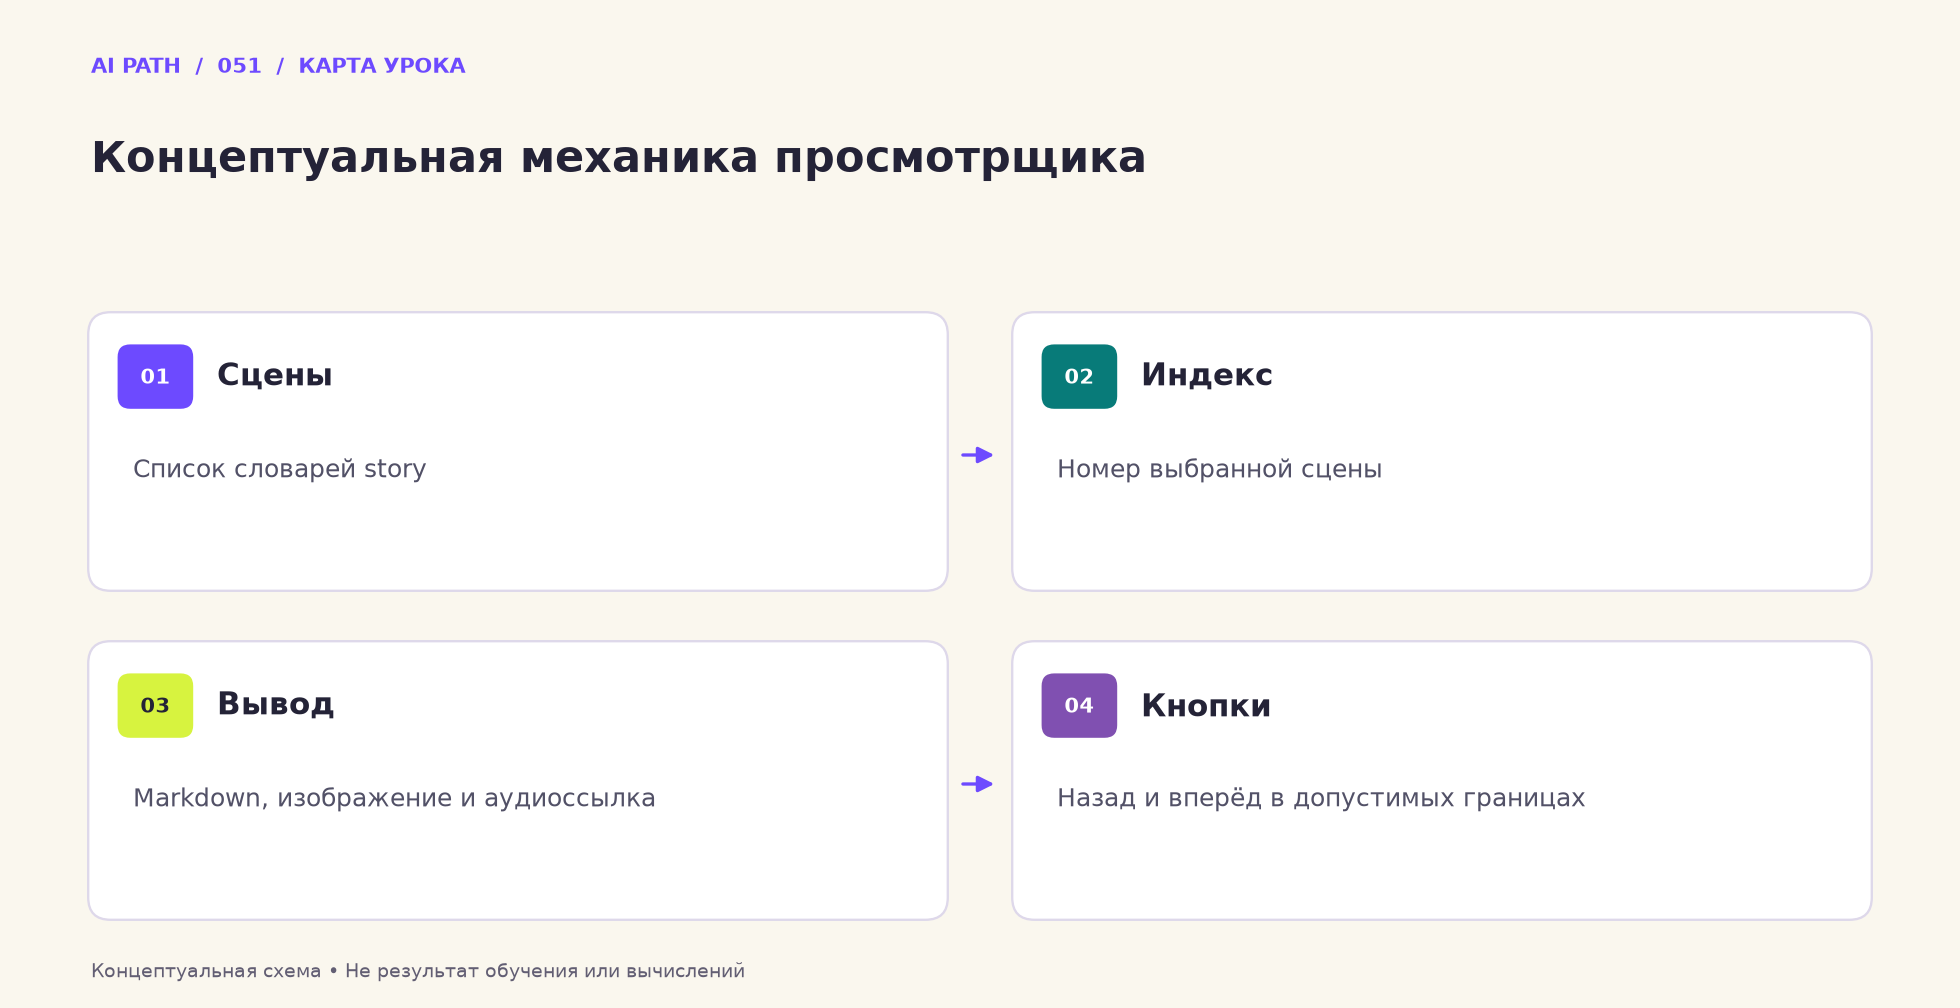

Схема показывает последовательность идей. Она не содержит результатов нового обучения или вычислений.

1. **Сцены** — Список словарей story
2. **Индекс** — Номер выбранной сцены
3. **Вывод** — Markdown, изображение и аудиоссылка
4. **Кнопки** — Назад и вперёд в допустимых границах

# Interactive Story

<a id="ai-051-section-01"></a>
## 01 · Описываем сцены данными

Каждая сцена содержит имя, текст, картинку и аудиоссылку. Поле text хранит фрагменты кода как строки: просмотрщик их показывает, а не исполняет.

_Далее — исходные ячейки учебного материала._

In [ ]:
story = [{'character': 'Alice', 'text': 'import os\nimport argparse\nfrom difflib import SequenceMatcher\nfrom itertools import cycle\nimport nbformat\nfrom nbformat.v4 import new_notebook, new_markdown_cell, new_code_cell\nimport subprocess', 'image': 'https://placehold.co/600x400?text=Image+0', 'audio': 'https://example.com/audio0.mp3'}, {'character': 'Bob', 'text': 'def collect_blocks(root, limit=None):\n    """Traverse directory and collect text blocks, removing duplicates and similar blocks."""\n    blocks = []\n    for dirpath, _, filenames in os.walk(root):\n        for name in filenames:\n            if name.lower().endswith((".md", ".txt", ".py")):\n                path = os.path.join(dirpath, name)\n                try:\n                    with open(path, "r", encoding="utf-8", errors="ignore") as f:\n                        content = f.read()\n                except Exception:\n                    continue\n                paragraphs = [p.strip() for p in content.split("\\n\\n") if p.strip()]\n                blocks.extend(paragraphs)\n                if limit and len(blocks) >= limit:\n                    blocks = blocks[:limit]\n                    break\n        if limit and len(blocks) >= limit:\n            break\n    return simplify_blocks(blocks)', 'image': 'https://placehold.co/600x400?text=Image+1', 'audio': 'https://example.com/audio1.mp3'}, {'character': 'Charlie', 'text': 'def simplify_blocks(blocks, threshold=0.9):\n    """Remove duplicate or highly similar blocks."""\n    unique = []\n    for block in blocks:\n        if not any(SequenceMatcher(None, block, u).ratio() >= threshold for u in unique):\n            unique.append(block)\n    return unique', 'image': 'https://placehold.co/600x400?text=Image+2', 'audio': 'https://example.com/audio2.mp3'}, {'character': 'Dana', 'text': 'def create_story(blocks):\n    characters = ["Alice", "Bob", "Charlie", "Dana"]\n    images = [f"https://placehold.co/600x400?text=Image+{i}" for i in range(len(blocks))]\n    audios = [f"https://example.com/audio{i}.mp3" for i in range(len(blocks))]\n    story = []\n    char_cycle = cycle(characters)\n    for i, block in enumerate(blocks):\n        story.append(\n            {\n                "character": next(char_cycle),\n                "text": block,\n                "image": images[i],\n                "audio": audios[i],\n            }\n        )\n    return story', 'image': 'https://placehold.co/600x400?text=Image+3', 'audio': 'https://example.com/audio3.mp3'}, {'character': 'Alice', 'text': 'def build_notebook(story, out_path):\n    nb = new_notebook()\n    nb.cells.append(new_markdown_cell("# Interactive Story"))\n    nb.cells.append(new_code_cell("story = {}".format(repr(story))))\n    navigation_code = """\nimport ipywidgets as widgets\nfrom IPython.display import display, Markdown\nindex = 0\nout = widgets.Output()', 'image': 'https://placehold.co/600x400?text=Image+4', 'audio': 'https://example.com/audio4.mp3'}]

<a id="ai-051-section-02"></a>
## 02 · Соединяем состояние и кнопки

show() выводит текущую сцену, а callbacks меняют индекс с проверкой границ. Статический GitHub-просмотр не заменяет работу виджетов в Jupyter.

_Далее — исходные ячейки учебного материала._

In [ ]:

import ipywidgets as widgets
from IPython.display import display, Markdown
index = 0
out = widgets.Output()

def show(i):
    block = story[i]
    md = f"### {block['character']}\n![]({block['image']})\n[Audio]({block['audio']})\n\n{block['text']}"
    with out:
        out.clear_output()
        display(Markdown(md))

show(index)

def next_block(_):
    global index
    if index < len(story) - 1:
        index += 1
        show(index)

def prev_block(_):
    global index
    if index > 0:
        index -= 1
        show(index)

next_btn = widgets.Button(description='Next')
prev_btn = widgets.Button(description='Previous')
next_btn.on_click(next_block)
prev_btn.on_click(prev_block)
display(widgets.HBox([prev_btn, next_btn]), out)


<a id="ai-051-practice"></a>
## Проверьте понимание

1. Что происходит при нажатии «назад» на первой и «вперёд» на последней сцене?
2. Почему код внутри text не создаёт новую историю во время показа?
3. Какие изображения и аудио нужно заменить, чтобы пример стал законченной историей?

### Один самостоятельный эксперимент

В рабочей копии добавьте шестую сцену с собственным изображением и счётчик «сцена N из M».

**Критерий успеха:** Все сцены доступны в обе стороны, счётчик соответствует индексу, а на границах нет ошибки или ухода за список.

<a id="ai-051-provenance"></a>
## Источники и ограничения

[Исходный ноутбук и его авторские материалы](https://github.com/safal207/students/blob/d848e04c8f8d6e3e8e42ce15fbd98c00612e0e17/interactive_story.ipynb) · репозиторий `safal207/students`.

Исходные подписи, ссылки, авторство, код, изображения и аудио сохранены. Длинные текстовые выводы могут быть сокращены с указанием источника. Архивные результаты не пересчитывались.

### Перед новым запуском

- Для кнопок требуется живое ядро и поддержка ipywidgets; статический экспорт не подтверждает интерактивность.
- Картинки являются внешними заглушками, а example.com/audio*.mp3 не подтверждают наличие воспроизводимого звука.
- Текущий контент демонстрирует структуру данных и вывод, но не является готовым художественным рассказом.

**Иллюстрации:** обложка направления AI PATH; карта урока подготовлена по содержимому исходных ячеек.